<a href="https://colab.research.google.com/github/pendo-kirahagaze/COU07506_240242484046_DSP_LAB/blob/main/COU07506_Week01_240242484046.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## WEEK 1 — PRE-LAB AND ANALYSIS QUESTIONS

### A. Pre-Lab Question

**Question: List three devices containing DSP and one signal each device processes.**

1. **Smartphone:** Processes digital audio signals during voice calls and recordings.
2. **Laptop:** Processes digital audio signals during multimedia playback.
3. **Wireless Earphones:** Process audio signals for sound reproduction and noise cancellation.

### B. Analysis Questions

**Question 1: What is the sampling rate of your recording? How many numbers are needed to store one minute in mono?**

The sampling rate of my recording is **[insert actual sampling rate] Hz**.

Number of samples = Sampling rate × Duration

= Sampling rate × 60 seconds

= **[insert calculated number] samples**.

Therefore, this number of samples is required to represent one minute of mono audio.

**Question 2: Why is a stem plot more appropriate than a continuous line for x(n)?**

A stem plot is appropriate because discrete-time signals are defined at individual integer sample indices. It displays each sample separately, whereas a continuous line may suggest values exist between the samples.

**Question 3: For a = 1.1, which property would the system violate if this exponential were its impulse response?**

The system would violate **Bounded-Input Bounded-Output (BIBO) stability**.

The exponential signal (1.1)ⁿu(n) grows continuously, and its absolute sum is infinite. Therefore, a system with this impulse response would be unstable.

### C. AI-Use Statement

ChatGPT (OpenAI) was used to assist with Python and GNU Octave code preparation, understanding signal-processing concepts, and explaining the laboratory questions.

The generated plots were checked against the expected behavior of elementary discrete-time signals. The audio-processing results were checked using the recording's sampling rate, duration and sample count.

The code and explanations should be reviewed and verified by the student before submission.

# DAR ES SALAAM INSTITUTE OF TECHNOLOGY

## DIGITAL SIGNAL PROCESSING LABORATORY

**Module Code:** COU 07506

**Student Name:** PENDO ANTHONY KIRAHAGAZE

**Registration Number:** 240242484046

**Class:** BENG24COE-3

**Academic Year:** 2026/2027

**Week:** 1

**Lab 0:** Setting Up the DSP Laboratory

### Task 1.1 — Your First Notebook

In [ ]:

# WEEK 1 - DSP LABORATORY
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory Setup Successful!")


DSP Laboratory Setup Successful!


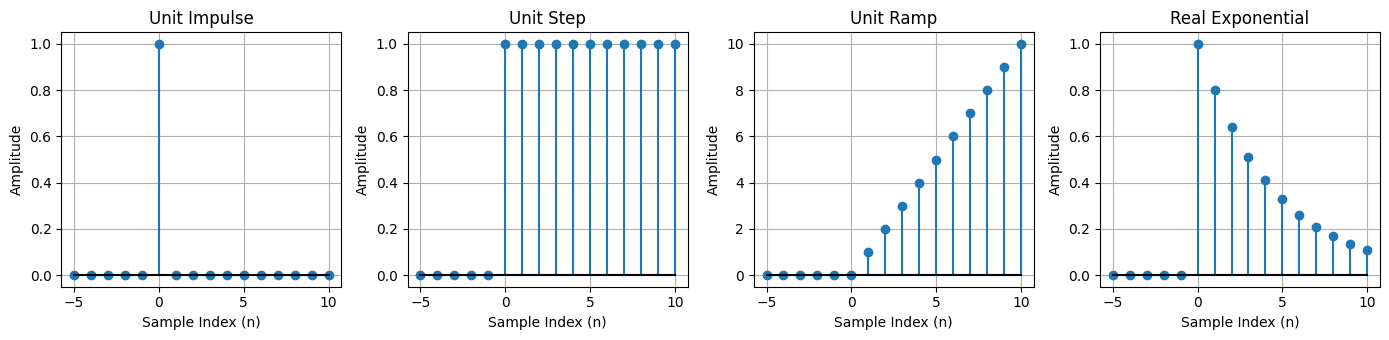

In [ ]:

# TASK 1.1 - Elementary Discrete-Time Signals

n = np.arange(-5, 11)

# Unit impulse
delta = (n == 0).astype(float)

# Unit step
step = (n >= 0).astype(float)

# Unit ramp
ramp = n * step

# Real exponential
expo = 0.8**n * step

# Plot all four signals
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

signals = [delta, step, ramp, expo]
titles = [
    "Unit Impulse",
    "Unit Step",
    "Unit Ramp",
    "Real Exponential"
]

for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample Index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


## Task 1.2 — Change the Parameters
### Part A: Exponential Signals

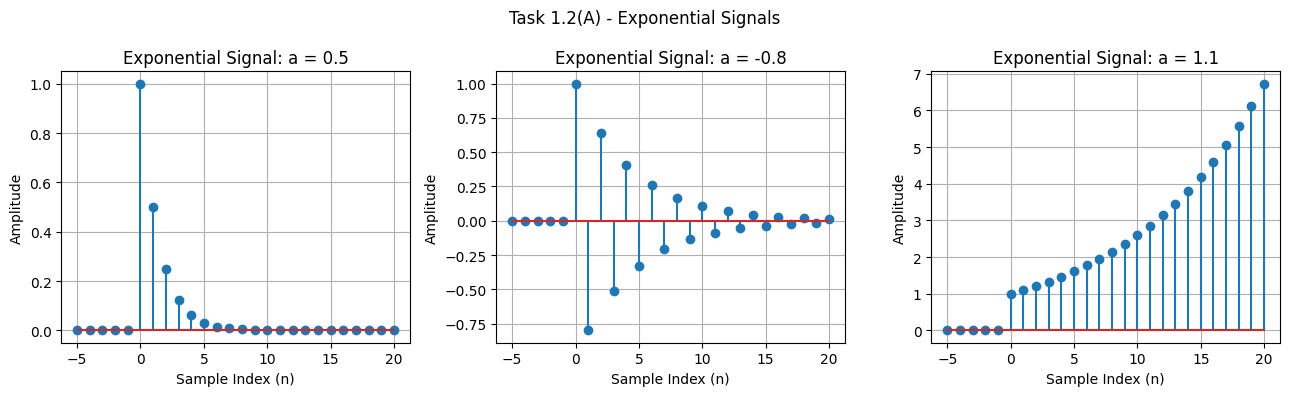

In [ ]:

# WEEK 1 — TASK 1.2 (A)
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 21)
step = (n >= 0).astype(float)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, a in zip(axes, a_values):
    x = (a**n) * step

    ax.stem(n, x)
    ax.set_title(f"Exponential Signal: a = {a}")
    ax.set_xlabel("Sample Index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.suptitle("Task 1.2(A) - Exponential Signals")
plt.tight_layout()
plt.show()


### Part B: Discrete-Time Cosine Signals

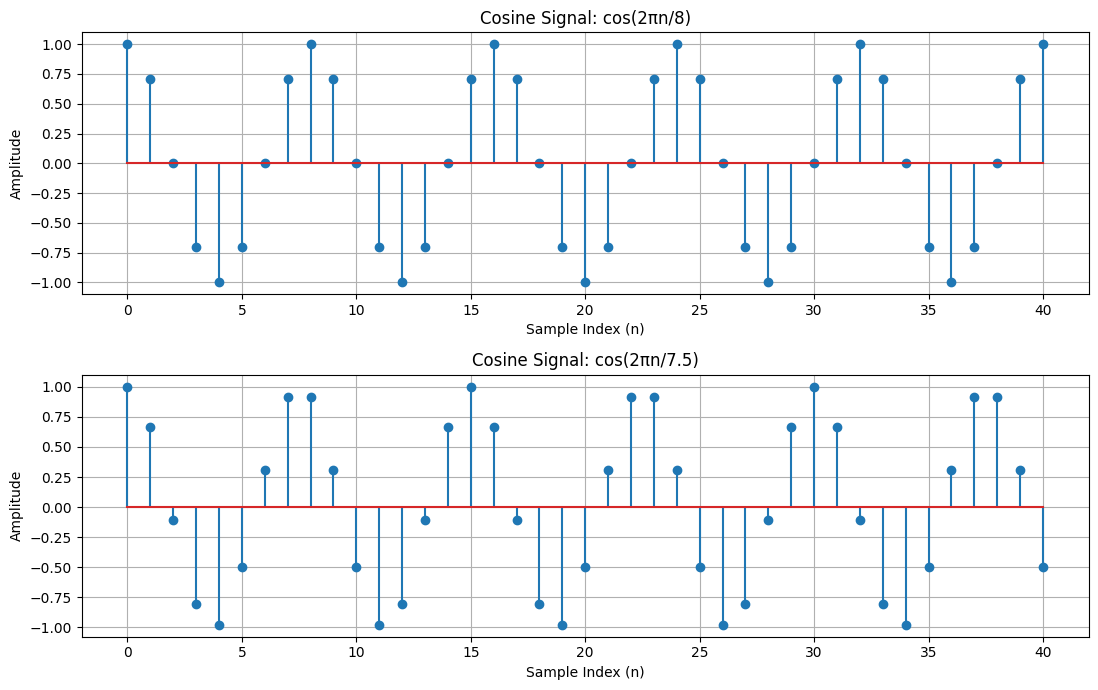

In [ ]:

# WEEK 1 — TASK 1.2 (B)
# Comparison of Discrete-Time Cosine Signals

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

axes[0].stem(n, x1)
axes[0].set_title("Cosine Signal: cos(2πn/8)")
axes[0].set_xlabel("Sample Index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2)
axes[1].set_title("Cosine Signal: cos(2πn/7.5)")
axes[1].set_xlabel("Sample Index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Task 1.2 — Observation and Discussion

**Part A: Exponential Signals**

For a = 0.5, the exponential signal decreases toward zero.

For a = −0.8, the signal alternates between positive and negative values while its magnitude gradually decreases.

For a = 1.1, the exponential signal increases with increasing sample index.

**Part B: Cosine Signals**

The first cosine signal, cos(2πn/8), repeats every 8 samples.

The second cosine signal, cos(2πn/7.5), repeats every 15 samples.

Both signals are periodic in discrete time because their normalized frequencies are rational multiples of 2π.

**Conclusion:** Changing the exponential parameter affects the growth, decay and sign of the signal, while changing the cosine frequency changes its fundamental period.

Sampling Rate: 44100 Hz
Duration: 4.9 seconds
Total Samples: 216064


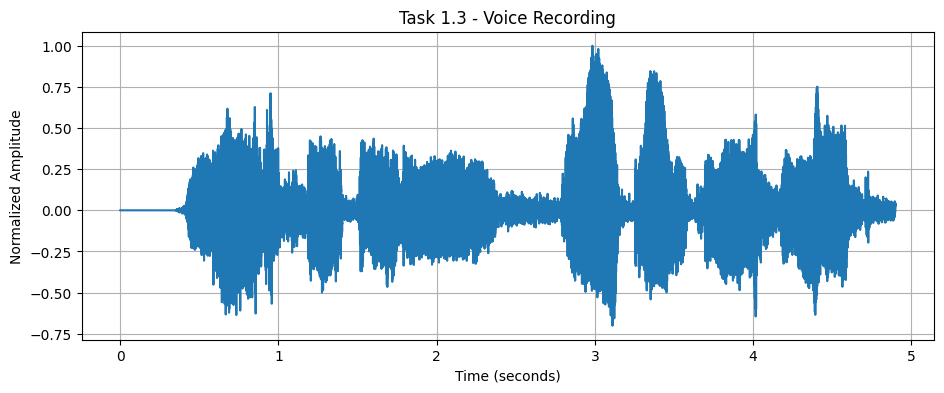

In [ ]:

# WEEK 1 — TASK 1.3
# Registration: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)
    peak = np.max(np.abs(x))

    if peak > 0:
        x = x / peak

    t = np.arange(len(x)) / fs

    print("Sampling Rate:", fs, "Hz")
    print("Duration:", round(len(x)/fs, 2), "seconds")
    print("Total Samples:", len(x))

    plt.figure(figsize=(11, 4))
    plt.plot(t, x)
    plt.title("Task 1.3 - Voice Recording")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Normalized Amplitude")
    plt.grid(True)
    plt.show()

    display(Audio(x, rate=fs))
else:
    print("Upload my_voice.wav first!")
